# Options: implied volatility smile, Greeks and the variance risk premium

**Objective:** take the real option chain of SPY (the S&P 500 ETF), calculate the implied volatility of every option with Black-Scholes, and build the smile, the term structure and the volatility surface. Then we calculate the Greeks of an at-the-money option and we check if options are "expensive": we compare the VIX with the volatility that really happened after.

**Data:** SPY option chain from Yahoo Finance (the result changes every time we run the notebook), VIX and 3-month T-bill from FRED, S&P 500 index from Yahoo Finance.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `yfinance` and `scipy`.

## Part 1. Libraries

In [1]:
import os
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.stats import norm
from scipy.optimize import brentq

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 2. Black-Scholes, implied volatility and Greeks

We include a continuous dividend yield q. The implied volatility is the sigma that makes the Black-Scholes price equal to the market price, so we find it with a root finder (Brent's method).

In [2]:
def bs_precio(S, K, T, r, q, sigma, tipo):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if tipo == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

def vol_implicita(precio, S, K, T, r, q, tipo):
    try:
        return brentq(lambda s: bs_precio(S, K, T, r, q, s, tipo) - precio, 0.0001, 5)
    except ValueError:
        return np.nan

def griegas(S, K, T, r, q, sigma, tipo):
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    signo = 1 if tipo == "call" else -1
    delta = signo * np.exp(-q * T) * norm.cdf(signo * d1)
    gamma = np.exp(-q * T) * norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega = S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T) / 100
    theta = (-S * np.exp(-q * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
             - signo * r * K * np.exp(-r * T) * norm.cdf(signo * d2)
             + signo * q * S * np.exp(-q * T) * norm.cdf(signo * d1)) / 365
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta}

## Part 3. The option chain

In [3]:
fred = lambda s: pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={s}", index_col=0, parse_dates=True, na_values=".").iloc[:, 0].dropna()
spy = yf.Ticker("SPY")
S = spy.history(period="5d")["Close"].iloc[-1]
r = fred("DGS3MO").iloc[-1] / 100
hoy = pd.Timestamp(date.today())
print("Spot:", round(S, 2), "| risk free 3m:", r)

vencimientos = [e for e in spy.options if 7 <= (pd.Timestamp(e) - hoy).days <= 400]
elegidos = sorted(set([vencimientos[0]] + vencimientos[2::max(1, len(vencimientos) // 10)] + [vencimientos[-1]]))
filas = []
for e in elegidos:
    cadena = spy.option_chain(e)
    for tipo, d in [("call", cadena.calls), ("put", cadena.puts)]:
        d = d[(d["bid"] > 0) & (d["ask"] > 0) & (d["openInterest"].fillna(0) > 0)].copy()
        d["mid"] = (d["bid"] + d["ask"]) / 2
        d["tipo"], d["expiry"] = tipo, e
        d["T"] = (pd.Timestamp(e) - hoy).days / 365
        filas.append(d[["strike", "bid", "ask", "mid", "openInterest", "tipo", "expiry", "T"]])
op = pd.concat(filas, ignore_index=True)
print("Expiries:", elegidos)
print("Quotes:", len(op))

Spot: 769.05 | risk free 3m: 0.042699999999999995


Expiries: ['2026-10-27', '2026-10-29', '2026-11-06', '2026-11-20', '2026-11-30', '2026-12-31', '2027-01-29', '2027-02-26', '2027-03-31', '2027-06-30', '2027-09-30']
Quotes: 3228


## Part 4. Forward price from put-call parity

Instead of assuming a dividend, we take the forward of each expiry from the put-call parity of the strikes closest to the spot: C - P = e^(-rT) (F - K).

In [4]:
fwd = {}
for e, g in op.groupby("expiry"):
    piv = g.pivot_table(index="strike", columns="tipo", values="mid").dropna()
    piv = piv.iloc[np.argsort(np.abs(piv.index.values - S))[:6]]      # the 6 strikes closest to the spot
    T = g["T"].iloc[0]
    fwd[e] = np.median(piv.index.values + np.exp(r * T) * (piv["call"].values - piv["put"].values))
op["F"] = op["expiry"].map(fwd)
op["q"] = r - np.log(op["F"] / S) / op["T"]       # implied dividend / carry
op["k"] = np.log(op["strike"] / op["F"])          # log-moneyness
print("Median implied carry (q):", round(op["q"].median(), 4))

Median implied carry (q): 0.0044


## Part 5. Implied volatility of the OTM options

We use only out-of-the-money options (puts below the forward and calls above), because they are more liquid. We also drop quotes with a very wide bid-ask spread or with an implied volatility very far from the strikes next to it (old prices).

In [5]:
otm = op[((op["tipo"] == "call") & (op["strike"] >= op["F"])) | ((op["tipo"] == "put") & (op["strike"] < op["F"]))]
otm = otm[otm["k"].between(-0.35, 0.2)].copy()
otm["iv"] = [vol_implicita(m, S, K, T, r, q, t) for m, K, T, q, t in zip(otm["mid"], otm["strike"], otm["T"], otm["q"], otm["tipo"])]
otm = otm.dropna(subset=["iv"])
otm = otm[otm["iv"].between(0.03, 1.5) & ((otm["ask"] - otm["bid"]) / otm["mid"] < 0.5)].sort_values(["expiry", "strike"])
mediana = otm.groupby("expiry")["iv"].transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
otm = otm[(otm["iv"] - mediana).abs() < 0.02]
otm.to_csv("data/spy_implied_vols.csv", index=False)
print("Options used:", len(otm))

Options used: 1792


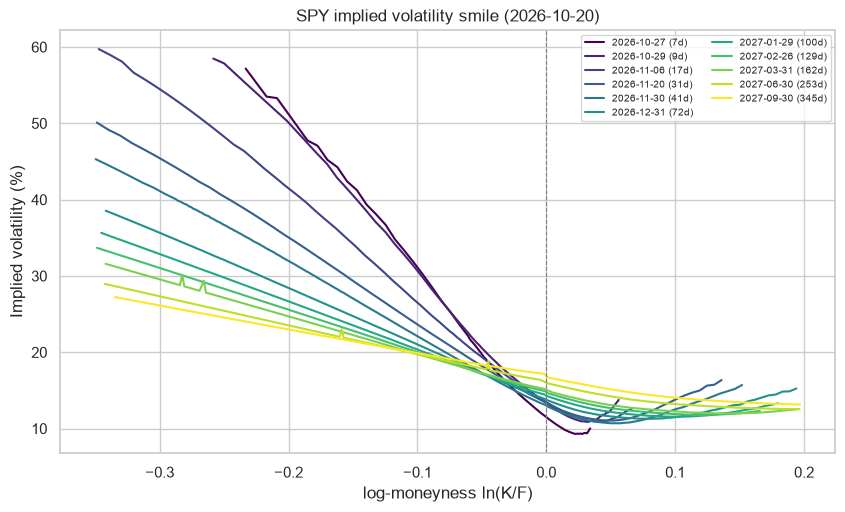

In [6]:
plt.figure(figsize=(10, 5.5))
colores = plt.cm.viridis(np.linspace(0, 1, otm["expiry"].nunique()))
for col, (e, g) in zip(colores, otm.groupby("expiry")):
    plt.plot(g["k"], g["iv"] * 100, color=col, label=f"{e} ({int(g['T'].iloc[0] * 365)}d)")
plt.axvline(0, color="grey", ls="--", lw=0.8)
plt.title(f"SPY implied volatility smile ({hoy.date()})")
plt.xlabel("log-moneyness ln(K/F)")
plt.ylabel("Implied volatility (%)")
plt.legend(fontsize=7, ncol=2)
plt.savefig("figures/iv_smile.png", bbox_inches="tight")
plt.show()

The smile is a "skew": puts with low strikes have much higher volatility than calls. The market pays a lot for protection against crashes, especially for short expiries.

In [7]:
def iv_en(g, k):
    g = g.sort_values("k")
    return np.interp(k, g["k"], g["iv"])

filas = []
for e, g in otm.groupby("expiry"):
    filas.append([e, int(g["T"].iloc[0] * 365), iv_en(g, 0) * 100, (iv_en(g, np.log(0.9)) - iv_en(g, 0)) * 100])
ts = pd.DataFrame(filas, columns=["expiry", "days", "atm_iv_%", "skew_90_%"]).set_index("expiry")
ts.round(2)

,days,atm_iv_%,skew_90_%
expiry,,,
2026-10-27,7,11.50,20.79
2026-10-29,9,13.34,18.44
2026-11-06,17,13.47,13.82
2026-11-20,31,13.39,10.85
2026-11-30,41,13.02,9.60
2026-12-31,72,13.81,7.62
2027-01-29,100,14.30,6.40
2027-02-26,129,14.77,5.55
2027-03-31,162,15.08,4.95


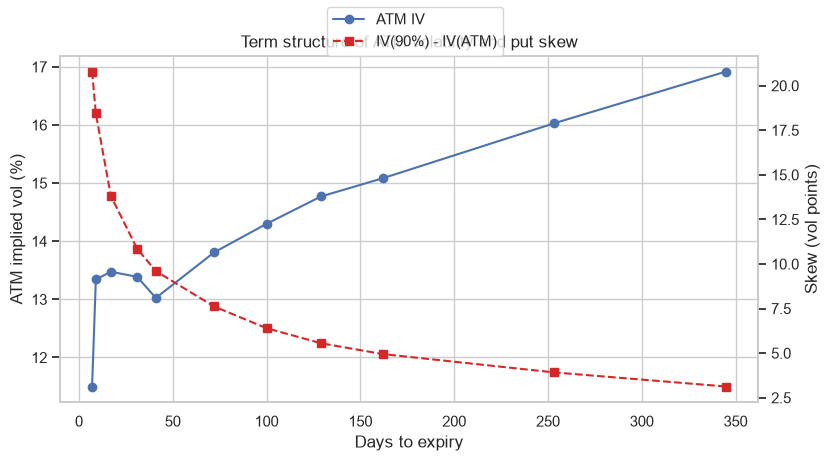

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(ts["days"], ts["atm_iv_%"], marker="o", label="ATM IV")
ax1.set_xlabel("Days to expiry")
ax1.set_ylabel("ATM implied vol (%)")
ax2 = ax1.twinx()
ax2.plot(ts["days"], ts["skew_90_%"], marker="s", ls="--", color="tab:red", label="IV(90%) - IV(ATM)")
ax2.set_ylabel("Skew (vol points)")
ax2.grid(False)
ax1.set_title("Term structure of ATM volatility and put skew")
fig.legend(loc="upper center")
plt.savefig("figures/term_structure.png", bbox_inches="tight")
plt.show()

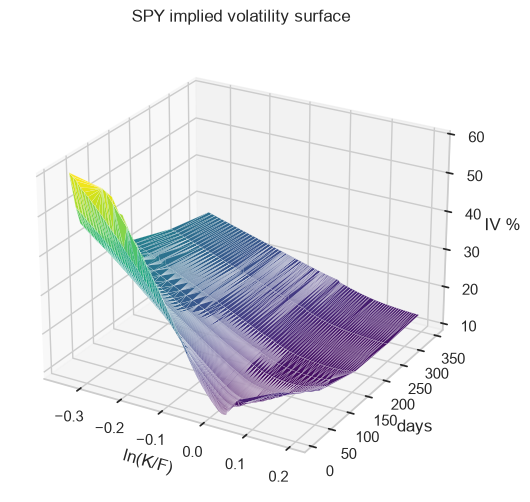

In [9]:
ax = plt.figure(figsize=(9, 6)).add_subplot(projection="3d")
ax.plot_trisurf(otm["k"], otm["T"] * 365, otm["iv"] * 100, cmap="viridis", lw=0.1)
ax.set_xlabel("ln(K/F)")
ax.set_ylabel("days")
ax.set_zlabel("IV %")
ax.view_init(25, -60)
ax.set_title("SPY implied volatility surface")
plt.savefig("figures/iv_surface.png", bbox_inches="tight")
plt.show()

## Part 6. Greeks of the ATM option with around 30 days

In [10]:
e30 = min(fwd, key=lambda e: abs((pd.Timestamp(e) - hoy).days - 30))
g = otm[otm["expiry"] == e30]
fila = g.iloc[np.argmin(np.abs(g["strike"].values - S))]
print("Expiry:", e30, "| strike:", fila["strike"], "| IV:", round(fila["iv"], 4))
pd.DataFrame({t: griegas(S, fila["strike"], fila["T"], r, fila["q"], fila["iv"], t) for t in ["call", "put"]}).T.round(4)

Expiry: 2026-11-20 | strike: 769.0 | IV: 0.1376


,delta,gamma,vega,theta
call,0.5531,0.0128,0.887,-0.2562
put,-0.4477,0.0128,0.887,-0.1463


## Part 7. Variance risk premium: VIX vs the volatility that came after

The VIX is the 30-day implied volatility of the S&P 500. We compare it with the realised volatility of the **next** 21 trading days.

Average premium (VIX - realised): 4.06 vol points
Share of days with VIX above the realised vol: 0.853
Worst day: 2020-02-19 -69.9


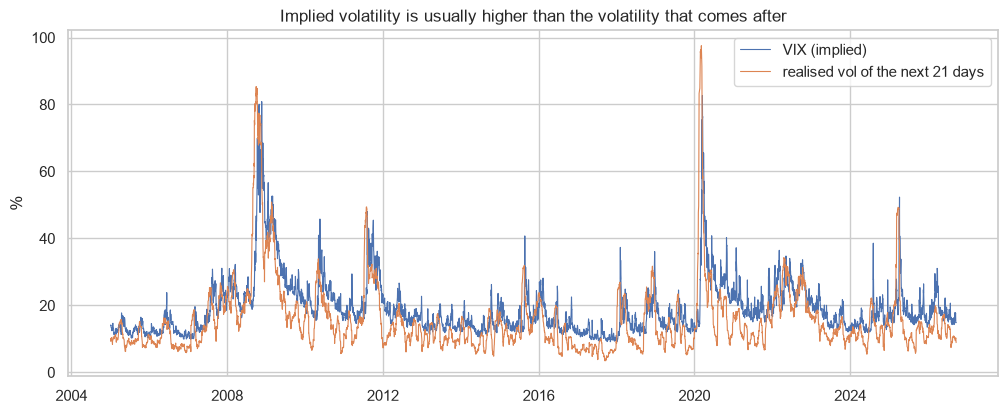

In [11]:
vix = fred("VIXCLS")
spx = yf.download("^GSPC", start="1990-01-01", auto_adjust=True, progress=False)["Close"].squeeze()
realizada = (np.log(spx).diff().rolling(21).std() * np.sqrt(252) * 100).shift(-21)
vrp = pd.DataFrame({"VIX": vix, "realised": realizada}).dropna()
vrp["premium"] = vrp["VIX"] - vrp["realised"]
print("Average premium (VIX - realised):", round(vrp["premium"].mean(), 2), "vol points")
print("Share of days with VIX above the realised vol:", round((vrp["premium"] > 0).mean(), 3))
print("Worst day:", vrp["premium"].idxmin().date(), round(vrp["premium"].min(), 1))

plt.figure(figsize=(12, 4.5))
plt.plot(vrp.loc["2005":, "VIX"], lw=0.8, label="VIX (implied)")
plt.plot(vrp.loc["2005":, "realised"], lw=0.8, label="realised vol of the next 21 days")
plt.title("Implied volatility is usually higher than the volatility that comes after")
plt.ylabel("%")
plt.legend()
plt.savefig("figures/vix_vs_realised.png", bbox_inches="tight")
plt.show()

## Conclusions

- The SPY smile has a strong put skew, much stronger for short expiries, and the ATM volatility grows with the maturity.
- Most of the time the VIX is higher than the volatility that comes after: on average selling volatility earns a premium of around 4 points. But in a crash (February 2020) the VIX was 70 points below what happened, so selling options gives small gains most of the time and very big losses sometimes.